In [ ]:
%pip install pandas numpy scikit-learn tensorflow keras shap lime matplotlib

In [ ]:
%pip install ucimlrepo

In [ ]:
%pip install xgboost

In [ ]:
%pip install imbalanced-learn

In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_curve, auc
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from seaborn import heatmap
import seaborn as sns

import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Path to your file
file_path = "../../data\\stroke\\healthcare-dataset-stroke-data.csv"

# Load dataset
df_corr = pd.read_csv(file_path)

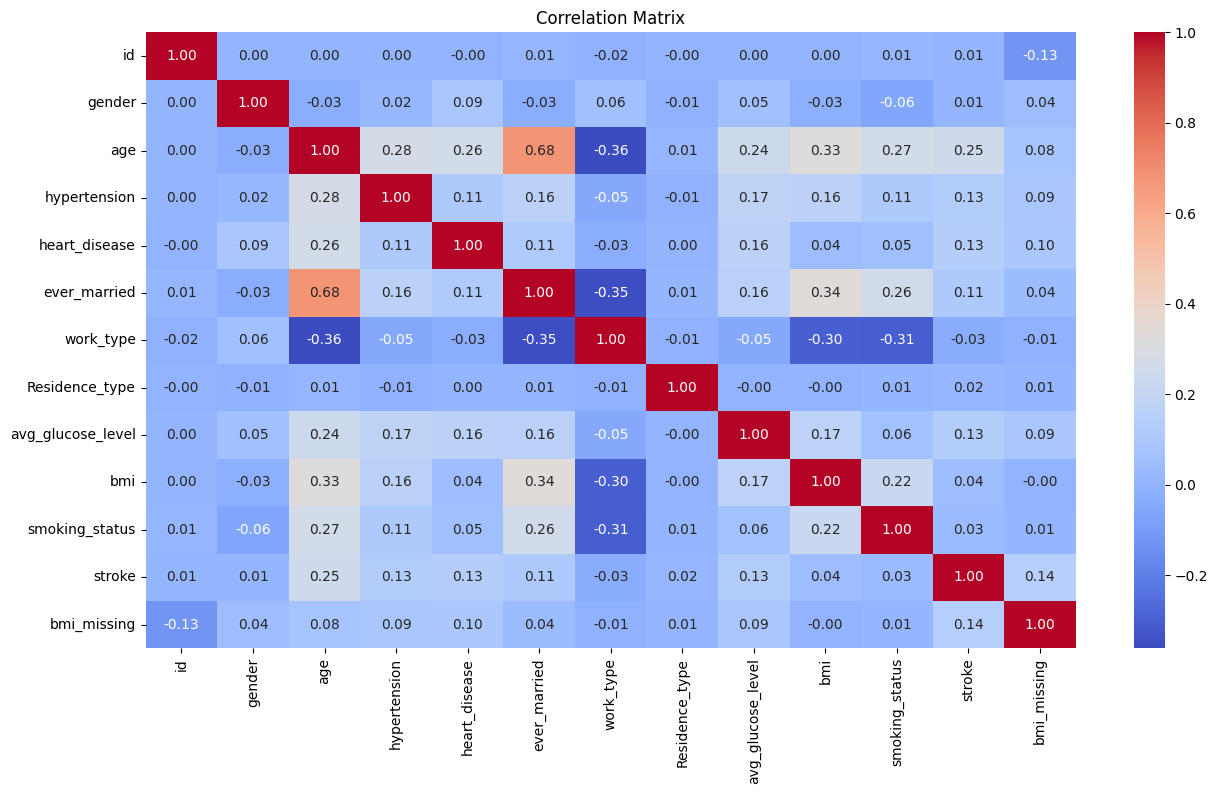

In [6]:
# Remove 'Other'
df_corr = df_corr[df_corr['gender'] != 'Other']

# CREATE bmi_missing HERE (correct dataframe)
df_corr['bmi_missing'] = df_corr['bmi'].isna().astype(int)

# Fill BMI AFTER creating the flag
df_corr['bmi'] = df_corr['bmi'].fillna(df_corr['bmi'].mean())

# Convert categorical → numeric
df_corr['gender'] = df_corr['gender'].map({'Male': 1, 'Female': 0})
df_corr['ever_married'] = df_corr['ever_married'].map({'Yes': 1, 'No': 0})
df_corr['Residence_type'] = df_corr['Residence_type'].map({'Urban': 1, 'Rural': 0})

df_corr['work_type'] = df_corr['work_type'].astype('category').cat.codes
df_corr['smoking_status'] = df_corr['smoking_status'].astype('category').cat.codes

# Compute correlation
corr_matrix = df_corr.corr()

plt.figure(figsize=(15,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')

plt.title("Correlation Matrix")
plt.show()

In [7]:
df = pd.read_csv(file_path)

df = df[df['gender'] != 'Other'].copy()
df['age'] = df['age'].astype(int)

df['bmi_missing'] = df['bmi'].isna().astype(int)
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())

df = df.drop('id', axis=1)

categorical_cols = [
    'gender',
    'smoking_status',
    'Residence_type',
    'work_type',
    'ever_married'
]

df = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

X_full = df.drop('stroke', axis=1) 
y = df['stroke']

corr = df.corr()['stroke'].abs()
selected_features = corr[corr > 0.1].index

X_selected = df[selected_features].drop('stroke', axis=1)

In [8]:
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y, test_size=0.2, random_state=42, stratify=y
)

X_train_sel, X_test_sel, _, _ = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

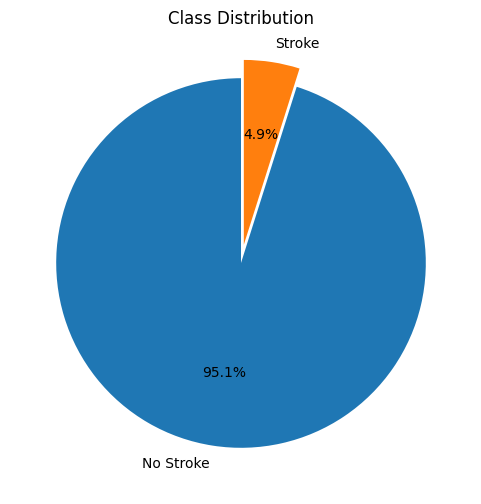

In [9]:
import matplotlib.pyplot as plt

counts = y.value_counts()

labels = ['No Stroke', 'Stroke']
sizes = counts.values

plt.figure(figsize=(6,6))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0, 0.1]
)

plt.title("Class Distribution")
plt.show()

In [10]:
from sklearn.preprocessing import StandardScaler

scaler_full = StandardScaler()
X_train_full = scaler_full.fit_transform(X_train_full)
X_test_full = scaler_full.transform(X_test_full)

scaler_sel = StandardScaler()
X_train_sel = scaler_sel.fit_transform(X_train_sel)
X_test_sel = scaler_sel.transform(X_test_sel)

In [11]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_curve, auc

def evaluate(y_true, y_pred, y_scores):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    return acc, f1, recall, fpr, tpr, roc_auc

In [12]:
def run_models(X_train, X_test, y_train, y_test):
    from imblearn.over_sampling import SMOTE

    # SMOTE (only on training set)
    #sm = SMOTE(random_state=42)
    #X_train, y_train = sm.fit_resample(X_train, y_train)

    results = {}

    # Logistic Regression
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    y_scores = lr.predict_proba(X_test)[:,1]
    results["Logistic Regression"] = evaluate(y_test, y_pred, y_scores)

    # Decision Tree
    dt = DecisionTreeClassifier()
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_test)
    y_scores = dt.predict_proba(X_test)[:,1]
    results["Decision Tree"] = evaluate(y_test, y_pred, y_scores)

    # Random Forest
    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    y_scores = rf.predict_proba(X_test)[:,1]
    results["Random Forest"] = evaluate(y_test, y_pred, y_scores)

    # SVM
    svm = SVC(probability=True)
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)
    y_scores = svm.predict_proba(X_test)[:,1]
    results["SVM"] = evaluate(y_test, y_pred, y_scores)

    # KNN
    knn = KNeighborsClassifier()
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    y_scores = knn.predict_proba(X_test)[:,1]
    results["KNN"] = evaluate(y_test, y_pred, y_scores)

    # XGBoost (optional)
    try:
        xgb = XGBClassifier(eval_metric='logloss')
        xgb.fit(X_train, y_train)
        y_pred = xgb.predict(X_test)
        y_scores = xgb.predict_proba(X_test)[:,1]
        results["XGBoost"] = evaluate(y_test, y_pred, y_scores)
    except:
        print("XGBoost not installed")

    return results

In [13]:
results_before = run_models(X_train_full, X_test_full, y_train, y_test)
results_after = run_models(X_train_sel, X_test_sel, y_train, y_test)

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

def run_dnn(X_train, X_test, y_train, y_test):
    # SMOTE
    #sm = SMOTE(random_state=42)
    #X_train, y_train = sm.fit_resample(X_train, y_train)

    model = Sequential()
    model.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=20, batch_size=50, verbose=0)

    y_scores = model.predict(X_test).ravel()
    y_pred = (y_scores > 0.5).astype(int)

    return evaluate(y_test, y_pred, y_scores)

In [15]:
results_before["DNN"] = run_dnn(X_train_full, X_test_full, y_train, y_test)
results_after["DNN"] = run_dnn(X_train_sel, X_test_sel, y_train, y_test)

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


In [ ]:
def plot_results(results, title):
    plot_models = [
        "Logistic Regression",
        "SVM",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ]

    # Define fixed color per model
    model_colors = {
        "Logistic Regression": "#4c4a86",  # blue
        "SVM": "#6783c1",                  # orange
        "KNN": "#dbe4f0",                  # green
        "Decision Tree": "#e5a39b",        # red
        "Random Forest": "#514c88",        # purple
        "XGBoost": "#6e89c9"               # brown
    }

    colors = [model_colors[m] for m in plot_models]

    acc = [results[m][0] for m in plot_models]
    f1 = [results[m][1] for m in plot_models]
    recall = [results[m][2] for m in plot_models]
    aucs = [results[m][5] for m in plot_models]

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    axs[0, 0].bar(plot_models, aucs, color=colors)
    axs[0, 0].set_title("AUC Comparison")
    axs[0, 0].set_ylabel("AUC")

    axs[0, 1].bar(plot_models, acc, color=colors)
    axs[0, 1].set_title("Accuracy Comparison")
    axs[0, 1].set_ylabel("Accuracy")

    axs[1, 0].bar(plot_models, f1, color=colors)
    axs[1, 0].set_title("F1 Comparison")
    axs[1, 0].set_ylabel("F1")

    axs[1, 1].bar(plot_models, recall, color=colors)
    axs[1, 1].set_title("Recall Comparison")
    axs[1, 1].set_ylabel("Recall")

    for ax in axs.flat:
        ax.tick_params(axis='x', rotation=45)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

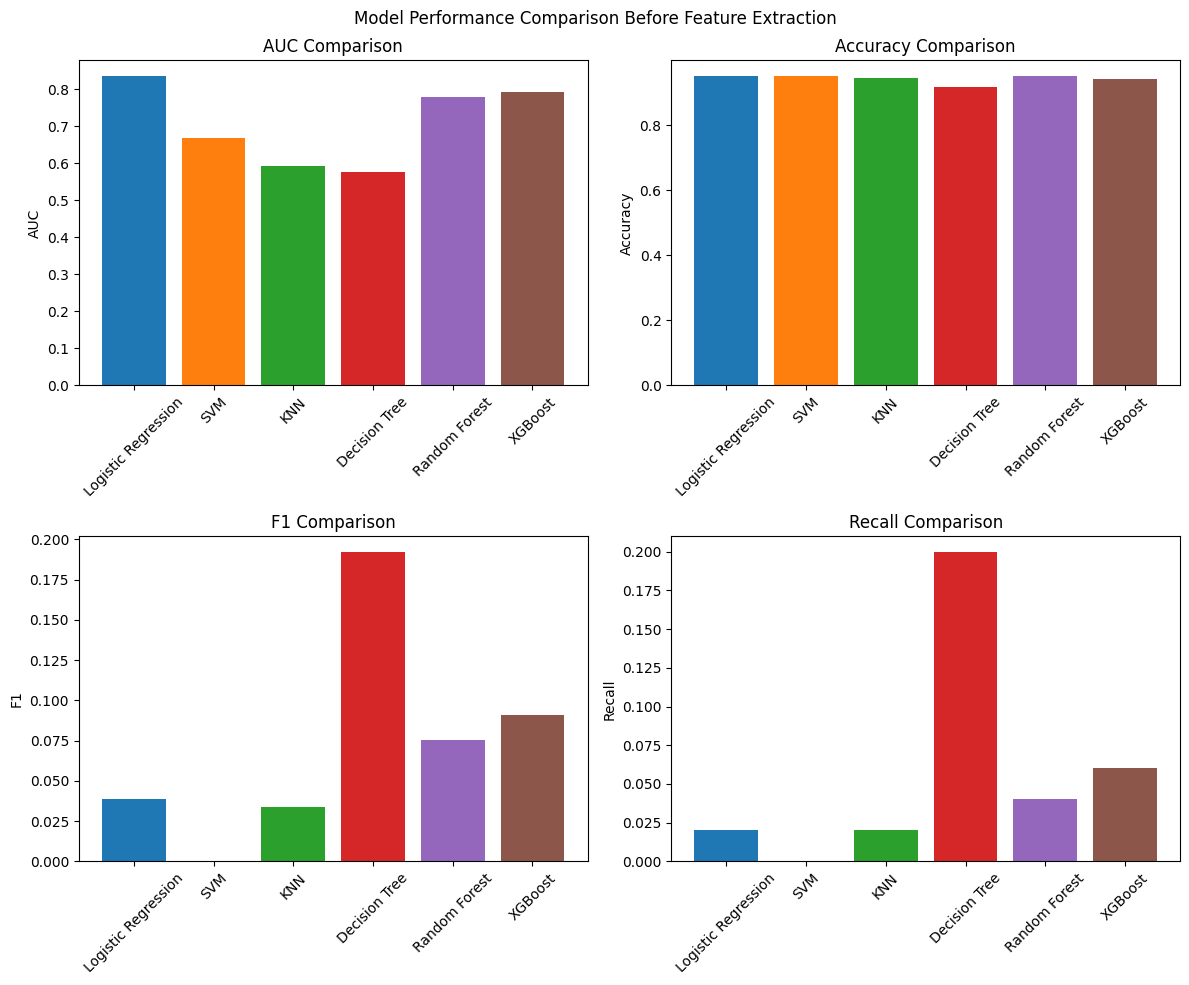

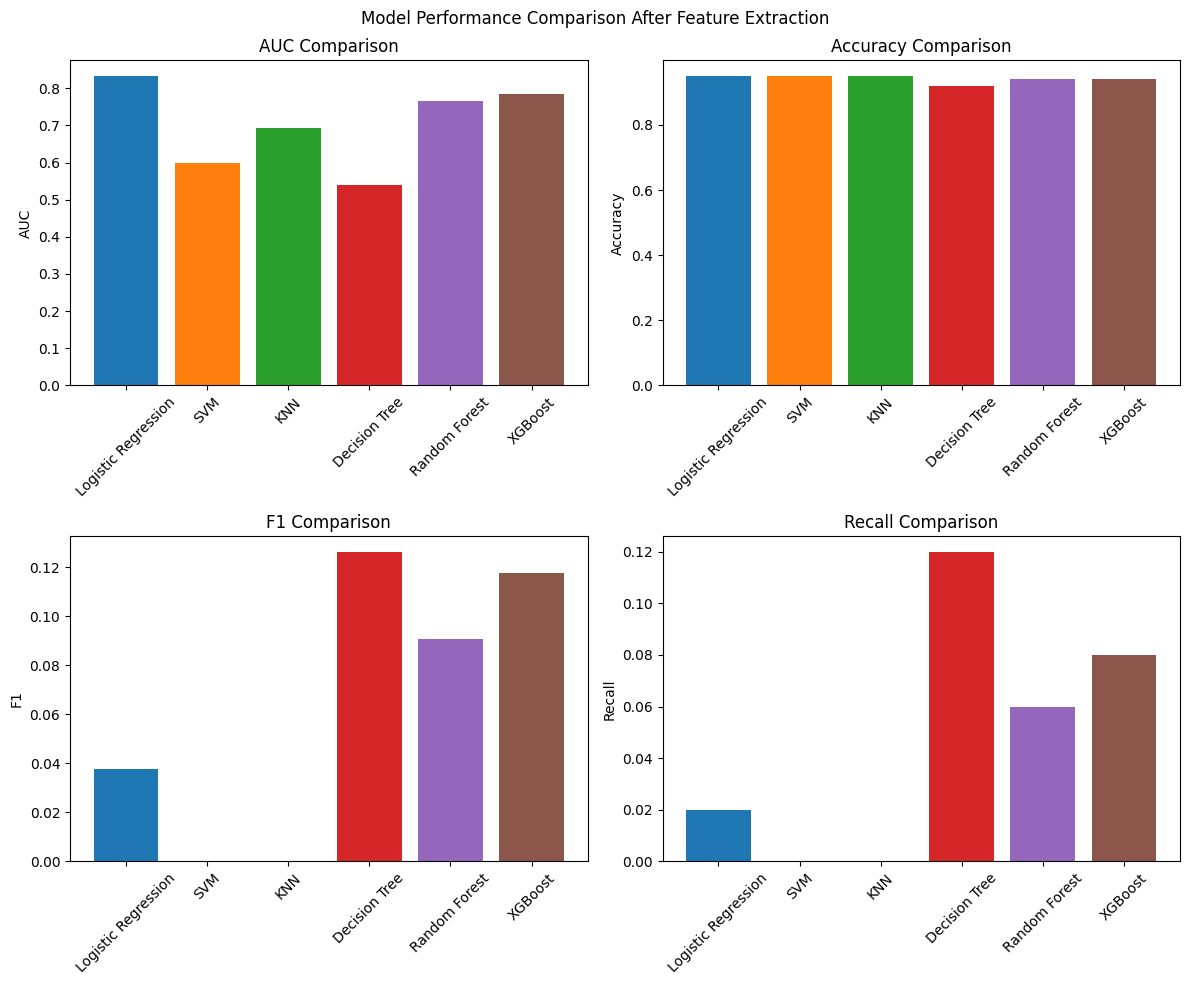

In [19]:
plot_results(results_before, "Model Performance Comparison Before Feature Extraction")
plot_results(results_after, "Model Performance Comparison After Feature Extraction")

In [20]:
import pandas as pd

dnn_before = results_before["DNN"]
dnn_after = results_after["DNN"]

dnn_table = pd.DataFrame({
    "Metric": ["Accuracy", "AUC"],
    "Before Feature Extraction": [round(dnn_before[0], 4), round(dnn_before[5], 4)],
    "After Feature Extraction": [round(dnn_after[0], 4), round(dnn_after[5], 4)]
})

print(dnn_table)

     Metric  Before Feature Extraction  After Feature Extraction
0  Accuracy                     0.9501                    0.9481
1       AUC                     0.8095                    0.8285


---- different pipeline -> same results

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_curve, auc

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# Optional for reproducibility
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# -----------------------------
# 1. Load and preprocess data
# -----------------------------
file_path = "../../data/stroke/healthcare-dataset-stroke-data.csv"
df = pd.read_csv(file_path)

df = df[df['gender'] != 'Other'].copy()
df['age'] = df['age'].astype(int)

df['bmi_missing'] = df['bmi'].isna().astype(int)
df['bmi'] = df['bmi'].fillna(df['bmi'].mean())

df = df.drop('id', axis=1)

categorical_cols = [
    'gender',
    'smoking_status',
    'Residence_type',
    'work_type',
    'ever_married'
]

df = pd.get_dummies(df, columns=categorical_cols, drop_first=False)

X_full = df.drop('stroke', axis=1)
y = df['stroke']

corr = df.corr()['stroke'].abs()
selected_features = corr[corr > 0.1].index
X_selected = df[selected_features].drop('stroke', axis=1)

In [10]:
# -----------------------------
# 2. Split data
# -----------------------------
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y, test_size=0.2, random_state=42, stratify=y
)

X_train_sel, X_test_sel, _, _ = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 3. Scale data
# -----------------------------
scaler_full = StandardScaler()
X_train_full = scaler_full.fit_transform(X_train_full)
X_test_full = scaler_full.transform(X_test_full)

scaler_sel = StandardScaler()
X_train_sel = scaler_sel.fit_transform(X_train_sel)
X_test_sel = scaler_sel.transform(X_test_sel)

In [11]:
# -----------------------------
# 4. Evaluation functions
# -----------------------------
def evaluate(y_true, y_pred, y_scores):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    return acc, f1, recall, fpr, tpr, roc_auc


In [12]:
def run_models(X_train, X_test, y_train, y_test):
    results = {}

    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    y_scores = lr.predict_proba(X_test)[:, 1]
    results["Logistic Regression"] = evaluate(y_test, y_pred, y_scores)

    dt = DecisionTreeClassifier()
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_test)
    y_scores = dt.predict_proba(X_test)[:, 1]
    results["Decision Tree"] = evaluate(y_test, y_pred, y_scores)

    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    y_scores = rf.predict_proba(X_test)[:, 1]
    results["Random Forest"] = evaluate(y_test, y_pred, y_scores)

    svm = SVC(probability=True)
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)
    y_scores = svm.predict_proba(X_test)[:, 1]
    results["SVM"] = evaluate(y_test, y_pred, y_scores)

    knn = KNeighborsClassifier()
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    y_scores = knn.predict_proba(X_test)[:, 1]
    results["KNN"] = evaluate(y_test, y_pred, y_scores)

    xgb = XGBClassifier(eval_metric='logloss')
    xgb.fit(X_train, y_train)
    y_pred = xgb.predict(X_test)
    y_scores = xgb.predict_proba(X_test)[:, 1]
    results["XGBoost"] = evaluate(y_test, y_pred, y_scores)

    return results

results_before = run_models(X_train_full, X_test_full, y_train, y_test)
results_after = run_models(X_train_sel, X_test_sel, y_train, y_test)

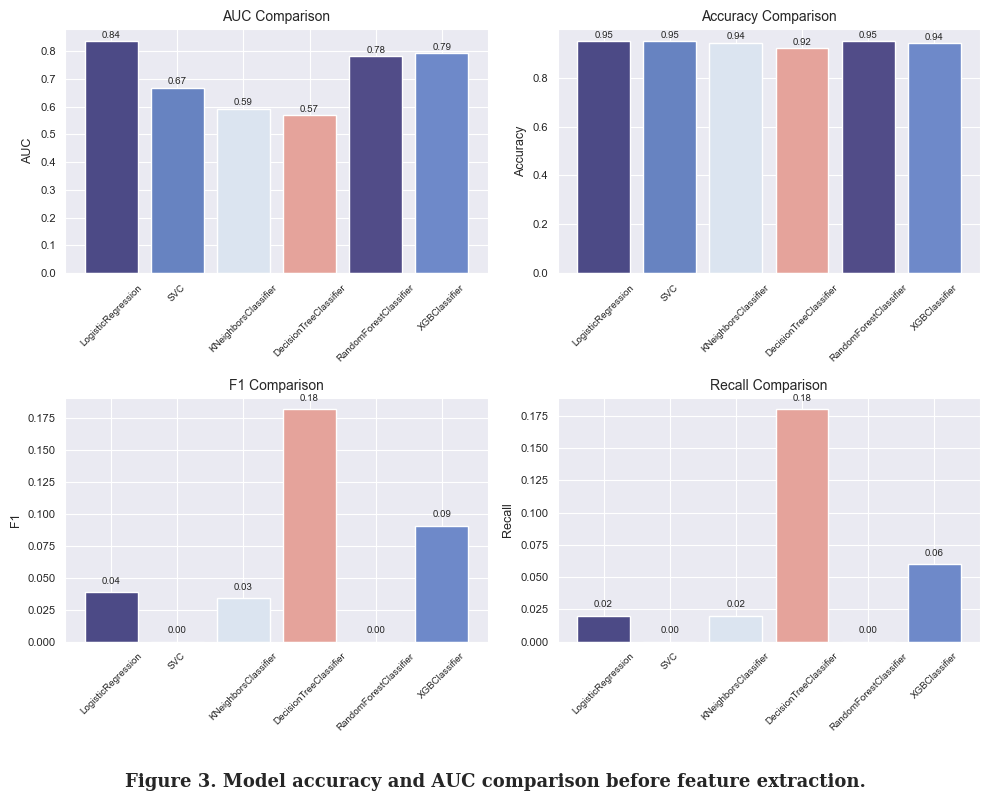

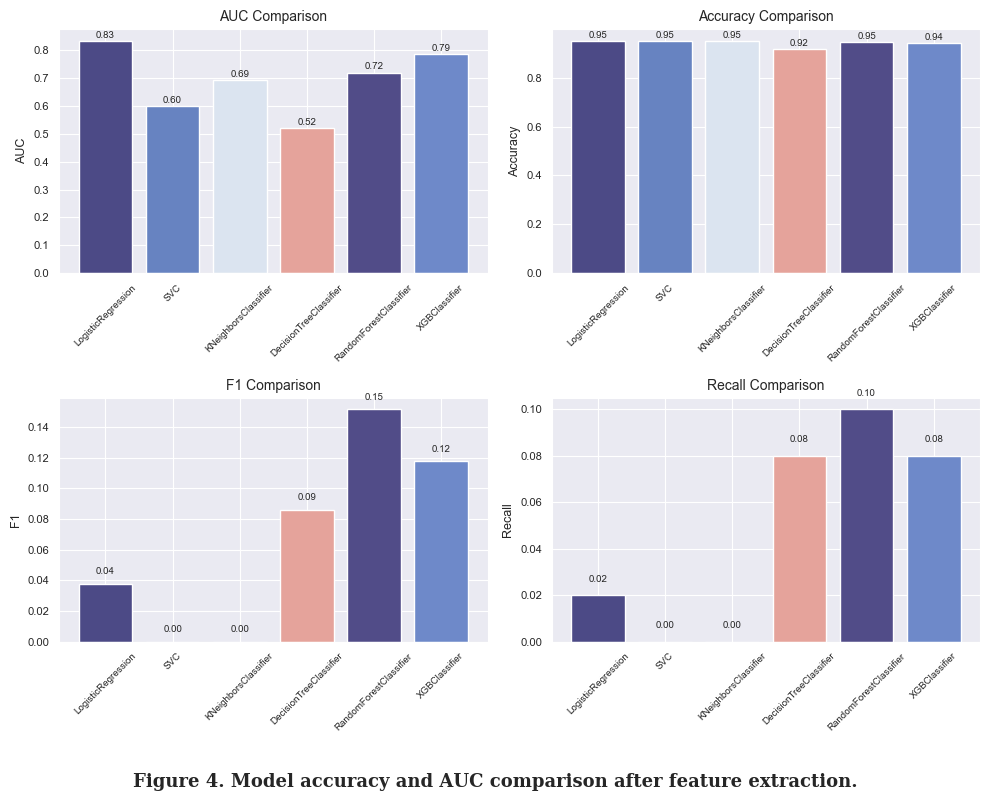

In [13]:
# -----------------------------
# 5. Paper-style plotting
# -----------------------------
def plot_results_paper_style(results, caption_text):
    sns.set_style("darkgrid")

    plot_models = [
        "Logistic Regression",
        "SVM",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ]

    label_map = {
        "Logistic Regression": "LogisticRegression",
        "SVM": "SVC",
        "KNN": "KNeighborsClassifier",
        "Decision Tree": "DecisionTreeClassifier",
        "Random Forest": "RandomForestClassifier",
        "XGBoost": "XGBClassifier"
    }

    display_labels = [label_map[m] for m in plot_models]

    model_colors = [
        "#4c4a86",
        "#6783c1",
        "#dbe4f0",
        "#e5a39b",
        "#514c88",
        "#6e89c9"
    ]

    acc = [results[m][0] for m in plot_models]
    f1 = [results[m][1] for m in plot_models]
    recall = [results[m][2] for m in plot_models]
    aucs = [results[m][5] for m in plot_models]

    fig, axs = plt.subplots(2, 2, figsize=(10, 8))

    metric_info = [
        ("AUC Comparison", aucs, "AUC"),
        ("Accuracy Comparison", acc, "Accuracy"),
        ("F1 Comparison", f1, "F1"),
        ("Recall Comparison", recall, "Recall")
    ]

    for ax, (title, values, ylabel) in zip(axs.flat, metric_info):
        bars = ax.bar(display_labels, values, color=model_colors)
        ax.set_title(title, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.tick_params(axis='x', rotation=45, labelsize=7)
        ax.tick_params(axis='y', labelsize=8)

        for bar, val in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f"{val:.2f}",
                ha='center',
                va='bottom',
                fontsize=7
            )

    plt.figtext(
        0.5, 0.01,
        caption_text,
        ha='center',
        fontsize=13,
        fontweight='bold',
        family='serif'
    )

    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

plot_results_paper_style(
    results_before,
    "Figure 3. Model accuracy and AUC comparison before feature extraction."
)

plot_results_paper_style(
    results_after,
    "Figure 4. Model accuracy and AUC comparison after feature extraction."
)


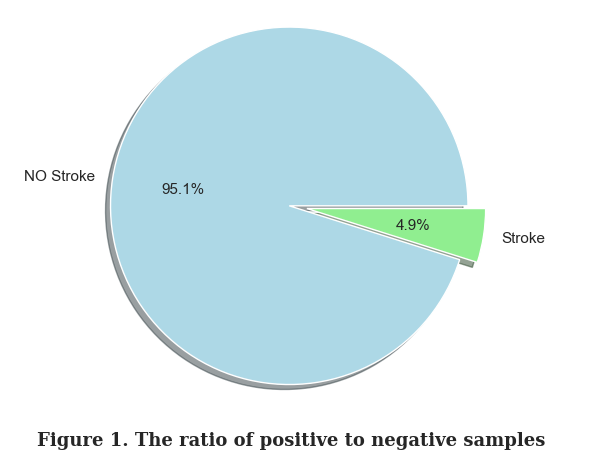

In [14]:
import matplotlib.pyplot as plt

counts = y.value_counts().sort_index()
# Assuming 0 = No Stroke, 1 = Stroke
sizes = [counts[0], counts[1]]
labels = ['NO Stroke', 'Stroke']
colors = ['#add8e6', '#90ee90']  # light blue, light green

fig, ax = plt.subplots(figsize=(6.2, 4.6))

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=0,
    explode=(0, 0.1),
    shadow=True,
    textprops={'fontsize': 11}
)

ax.axis('equal')

plt.figtext(
    0.5, 0.02,
    'Figure 1. The ratio of positive to negative samples',
    ha='center',
    fontsize=13,
    fontweight='bold',
    family='serif'
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()


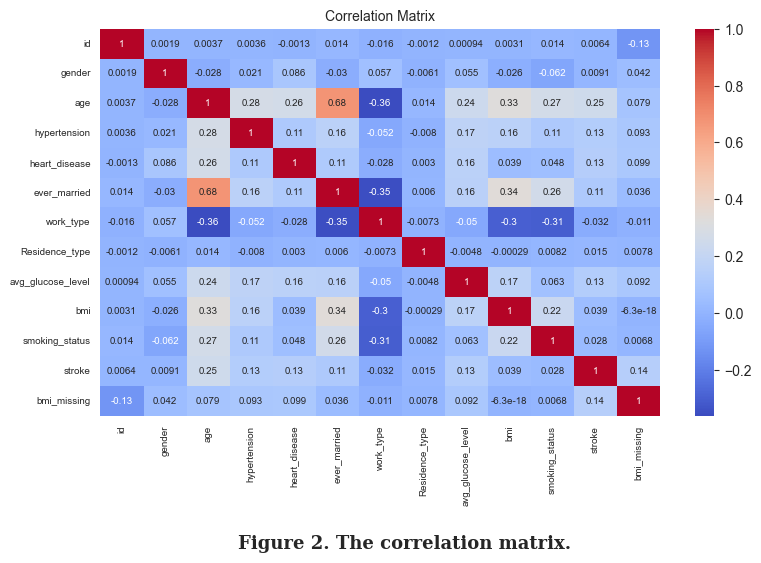

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "../../data/stroke/healthcare-dataset-stroke-data.csv"
df_corr = pd.read_csv(file_path)

# Remove 'Other'
df_corr = df_corr[df_corr['gender'] != 'Other'].copy()

# Create bmi_missing
df_corr['bmi_missing'] = df_corr['bmi'].isna().astype(int)

# Fill BMI
df_corr['bmi'] = df_corr['bmi'].fillna(df_corr['bmi'].mean())

# Convert categorical to numeric
df_corr['gender'] = df_corr['gender'].map({'Male': 1, 'Female': 0})
df_corr['ever_married'] = df_corr['ever_married'].map({'Yes': 1, 'No': 0})
df_corr['Residence_type'] = df_corr['Residence_type'].map({'Urban': 1, 'Rural': 0})
df_corr['work_type'] = df_corr['work_type'].astype('category').cat.codes
df_corr['smoking_status'] = df_corr['smoking_status'].astype('category').cat.codes

corr_matrix = df_corr.corr()

fig, ax = plt.subplots(figsize=(8.2, 5.6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2g",
    cmap="coolwarm",
    cbar=True,
    annot_kws={"size": 7},
    ax=ax
)

ax.set_title("Correlation Matrix", fontsize=10)
ax.tick_params(axis='x', labelrotation=90, labelsize=7)
ax.tick_params(axis='y', labelsize=7)

plt.figtext(
    0.5, 0.01,
    'Figure 2. The correlation matrix.',
    ha='center',
    fontsize=13,
    fontweight='bold',
    family='serif'
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


In [16]:
# -----------------------------
# 4. DNN evaluation function
# -----------------------------
from sklearn.metrics import accuracy_score, roc_curve, auc

def run_dnn(X_train, X_test, y_train, y_test):
    model = Sequential()
    model.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=20, batch_size=50, verbose=0)

    y_scores = model.predict(X_test).ravel()
    y_pred = (y_scores > 0.5).astype(int)

    acc = accuracy_score(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_scores)
    roc_auc = auc(fpr, tpr)

    return acc, roc_auc

# -----------------------------
# 5. Compute DNN results
# -----------------------------
dnn_before_acc, dnn_before_auc = run_dnn(X_train_full, X_test_full, y_train, y_test)
dnn_after_acc, dnn_after_auc = run_dnn(X_train_sel, X_test_sel, y_train, y_test)

dnn_table = pd.DataFrame({
    "Metric": ["Accuracy", "AUC"],
    "Before Feature Extraction": [round(dnn_before_acc, 4), round(dnn_before_auc, 4)],
    "After Feature Extraction": [round(dnn_after_acc, 4), round(dnn_after_auc, 4)]
})

print(dnn_table)


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
     Metric  Before Feature Extraction  After Feature Extraction
0  Accuracy                     0.9511                    0.9481
1       AUC                     0.8063                    0.8323
